In [2]:
from pathlib import Path
import os

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDLEAD")
os.chdir(repo_root)

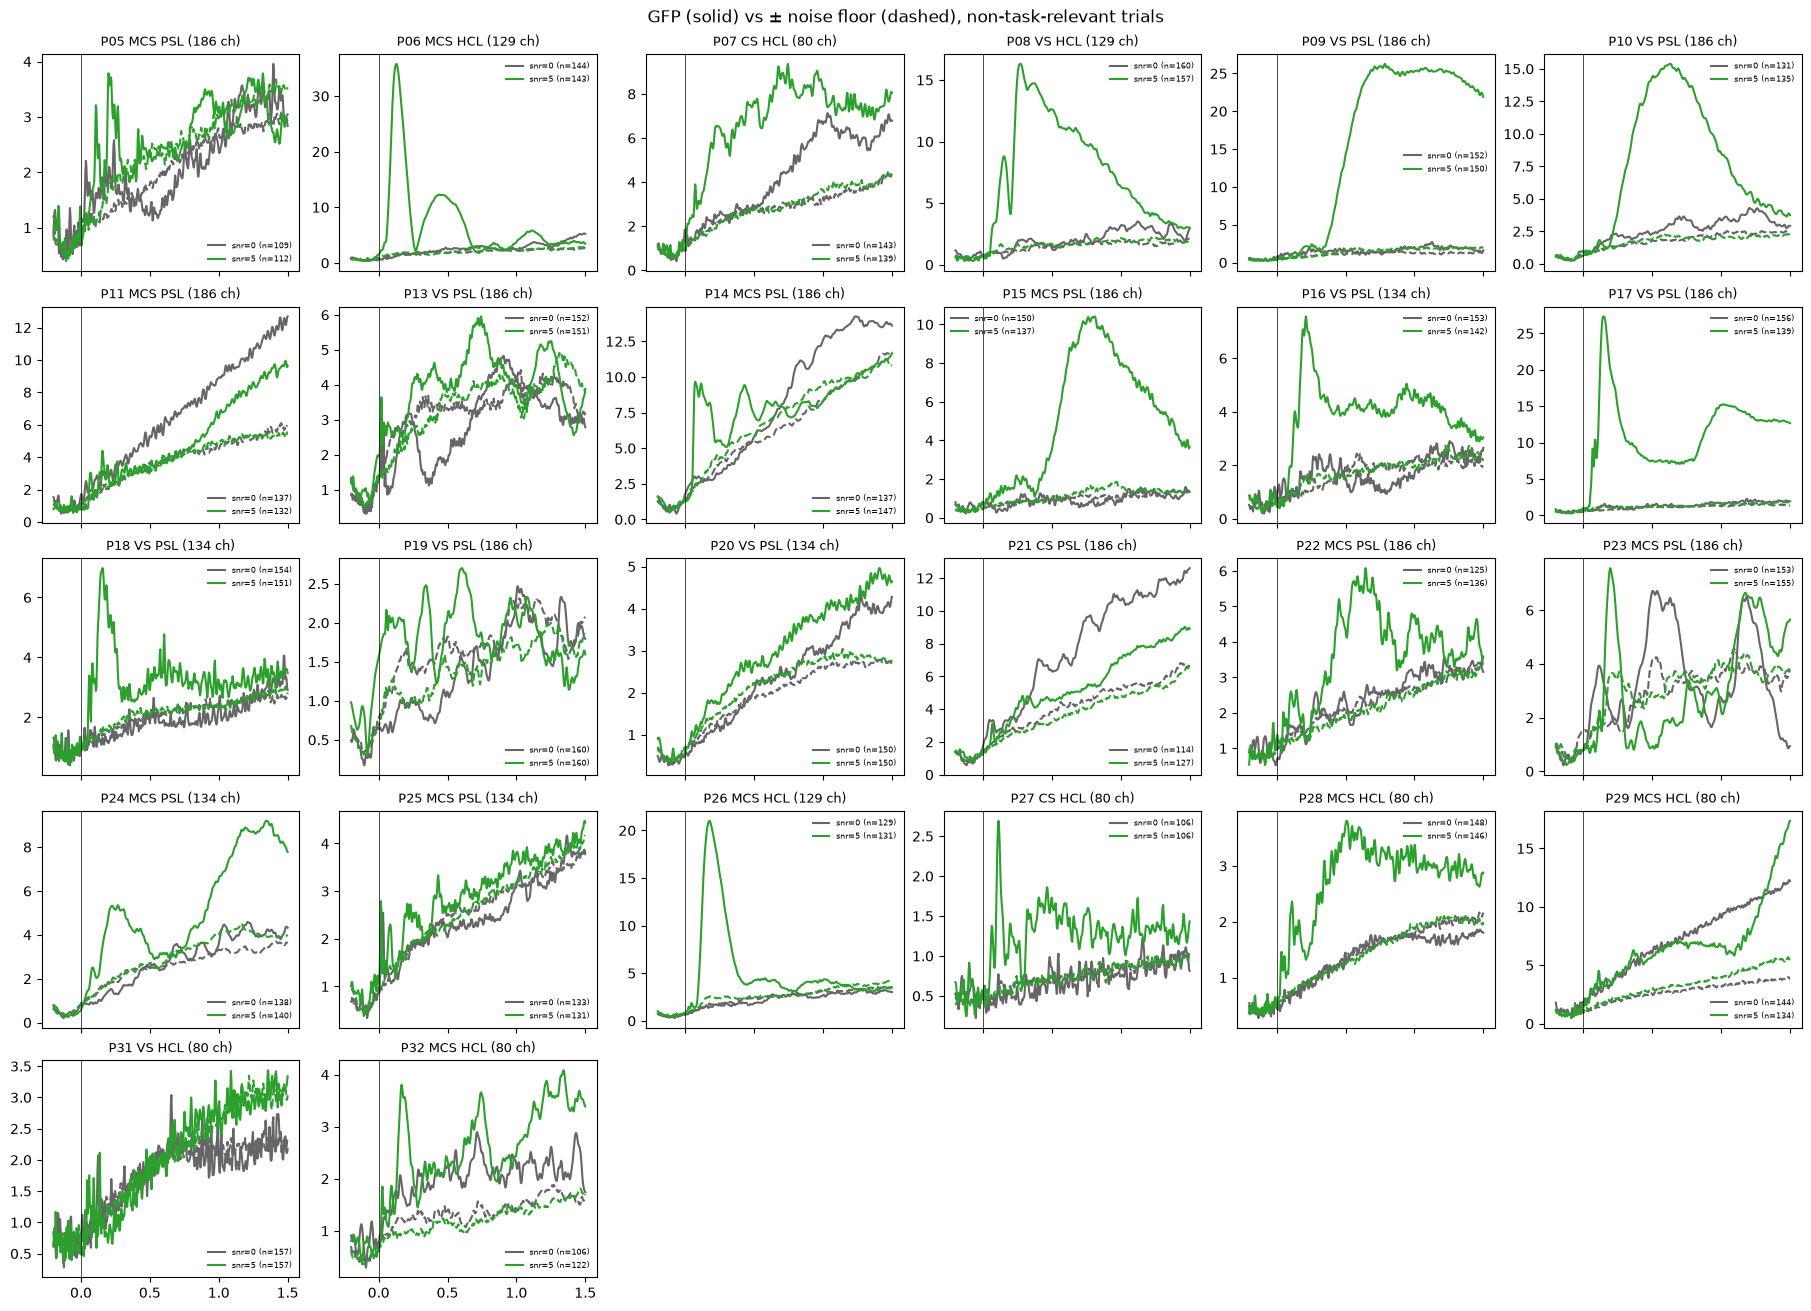

snr           0      5
group sub             
CS    P07  1.70   1.91
      P21  1.95   1.49
      P27  0.96   1.43
MCS   P05  1.11   0.93
      P06  1.49   1.65
      P11  2.01   1.61
      P14  1.34   0.99
      P15  0.99   4.22
      P22  1.05   1.33
      P23  0.96   1.33
      P24  1.22   2.03
      P25  1.00   1.07
      P26  0.91   0.96
      P28  0.87   1.47
      P29  2.97   2.08
      P32  1.36   2.19
VS    P08  1.57   2.13
      P09  1.54  12.88
      P10  1.46   2.53
      P13  0.87   0.98
      P16  1.12   1.67
      P17  1.31   8.22
      P18  1.03   1.23
      P19  0.96   0.96
      P20  1.39   1.53
      P31  0.97   0.98

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

EP_DIR = repo_root / "Study3" / "epochs" / "hp0.1_lp40"
BL = (-0.2, 0.0)


def gfp_vs_floor(ep, cond_col="snr", seed=0, n_perm=20):
    rng = np.random.default_rng(seed)
    ep = ep[~ep.metadata["task_relevant"].astype(bool).to_numpy()]
    t = ep.times
    X = ep.get_data(picks="eeg")
    X = X - X[:, :, (t >= BL[0]) & (t < BL[1])].mean(-1, keepdims=True)
    rms = lambda a: np.sqrt((a ** 2).mean(0)) * 1e6
    out = {}
    for c in sorted(ep.metadata[cond_col].unique()):
        Xc = X[(ep.metadata[cond_col] == c).to_numpy()]
        s = rng.permutation(np.r_[np.ones(len(Xc) // 2), -np.ones(len(Xc) - len(Xc) // 2)])
        fl = np.median([rms((rng.permutation(s)[:, None, None] * Xc).mean(0)) for _ in range(n_perm)], axis=0)
        out[c] = (rms(Xc.mean(0)), fl, len(Xc))
    return t, out


files = sorted(EP_DIR.glob("P*-epo.fif"))
fig, axes = plt.subplots(int(np.ceil(len(files) / 6)), 6, figsize=(18, 2.6 * np.ceil(len(files) / 6)),
                         sharex=True, squeeze=False, layout="constrained")
rows = []
for ax, f in zip(axes.flat, files):
    sub = f.name.replace("-epo.fif", "")
    ep = mne.read_epochs(f, preload=True, verbose="error")
    info = json.loads((EP_DIR / f"{sub}_qc.json").read_text())
    t, out = gfp_vs_floor(ep)
    late = (t >= 1.0) & (t <= 1.5)
    for c, col in [(0, "0.4"), (max(out), "tab:green")]:
        g, fl, n = out[c]
        ax.plot(t, g, color=col, label=f"snr={c} (n={n})")
        ax.plot(t, fl, color=col, ls="--")
        rows.append({"sub": sub, "group": info.get("group"), "site": info.get("site"), "snr": c,
                     "gfp_late": g[late].mean(), "floor_late": fl[late].mean(),
                     "ratio_late": g[late].mean() / fl[late].mean()})
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"{sub} {info.get('group')} {info.get('site')} ({len(ep.ch_names)} ch)", fontsize=9)
    ax.legend(fontsize=6, frameon=False)
for ax in axes.flat[len(files):]:
    ax.axis("off")
fig.suptitle("GFP (solid) vs ± noise floor (dashed), non-task-relevant trials")
plt.show()

ratios = pd.DataFrame(rows)
ratios.pivot_table(index=["group", "sub"], columns="snr", values="ratio_late").round(2)

In [4]:
def nearest_lag(a, b):
    i = np.clip(np.searchsorted(b, a), 1, len(b) - 1)
    prev, nxt = b[i - 1] - a, b[i] - a
    return np.where(np.abs(prev) < np.abs(nxt), prev, nxt)


def din_lags(ip):
    sub = f"P{ip:02d}"
    raw = mne.io.read_raw_brainvision(repo_root / "Study3" / sub / f"{sub}.vhdr", preload=False, verbose="error")
    a = raw.annotations
    on = a.onset - (raw.first_time if a.orig_time is not None else 0.0)
    desc = np.array([str(d).split("/")[-1] for d in a.description])
    stim = np.sort(on[np.char.startswith(desc.astype(str), "S1")])
    rows = []
    for d in np.unique(desc):
        if not d.upper().startswith("DI"):
            continue
        b = np.sort(on[desc == d])
        if len(b) < 2:
            continue
        lag = nearest_lag(stim, b) * 1e3
        rows.append({"sub": sub, "din": d, "n_din": len(b), "n_stim": len(stim),
                     "median_ms": np.median(lag), "iqr_ms": np.subtract(*np.percentile(lag, [75, 25])),
                     "p5_ms": np.percentile(lag, 5), "p95_ms": np.percentile(lag, 95)})
    return rows


units = [int(p[1:]) for p in pd.read_csv(repo_root / "Study3" / "participants.tsv", sep="\t")["participant"]]
lags = pd.DataFrame([r for ip in units if (repo_root / "Study3" / f"P{ip:02d}" / f"P{ip:02d}.vhdr").exists()
                     for r in din_lags(ip)])
lags.round(1)

,sub,din,n_din,n_stim,median_ms,iqr_ms,p5_ms,p95_ms
0,P05,DI10,2,1040,-1867011.0,1762967.0,-3673501.2,-235572.6
1,P05,DI20,4,1040,-182346.0,502332.0,-608113.2,457278.8
2,P05,DI21,3,1040,54763.0,746913.0,-995637.2,616271.4
3,P05,DI30,4,1040,-183319.0,516033.5,-613237.2,457907.3
4,P05,DI31,3,1040,53750.0,746914.5,-996647.2,615255.4
...,...,...,...,...,...,...,...,...
313,P32,DI51,4,790,-105654.0,498552.5,-423628.0,377007.4
314,P32,DI52,4,790,-106030.0,499352.0,-424412.0,376033.7
315,P32,DI53,4,790,-102650.0,499480.5,-422006.0,378872.0
316,P32,DI60,400,790,-496.0,2835.0,-3704.4,5043.9


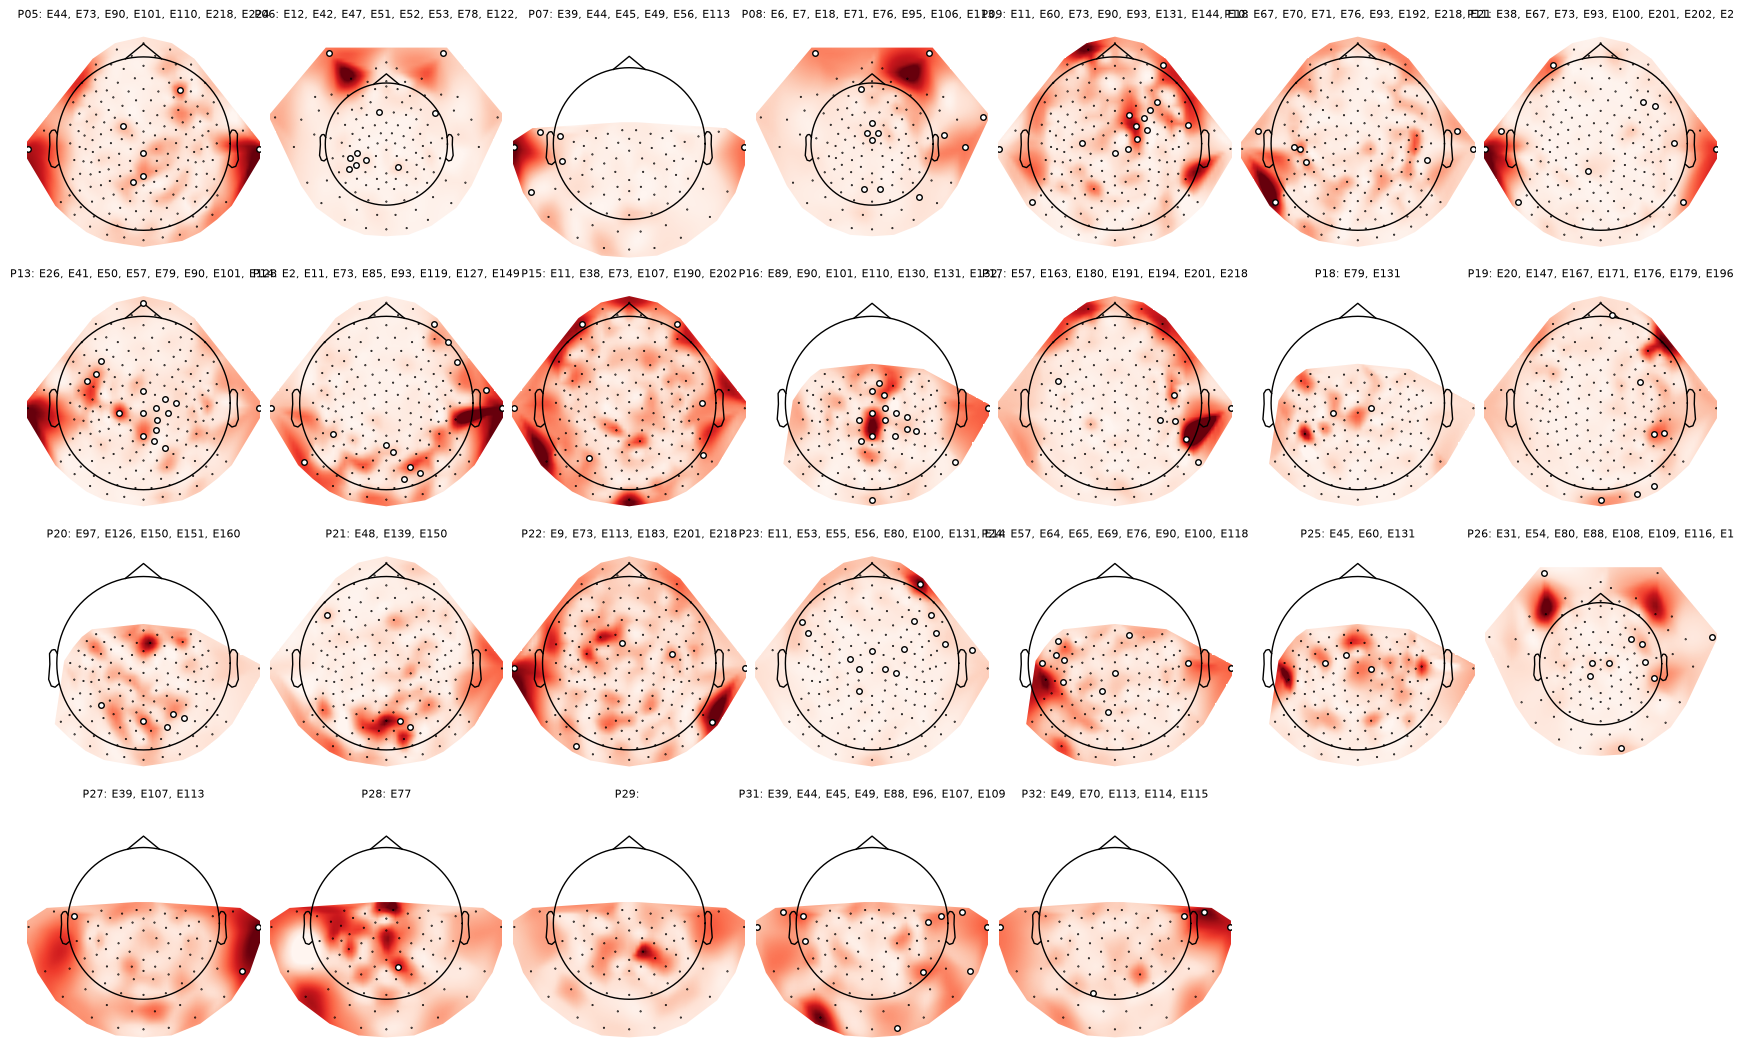

,ch,evoked_resid_uV,z_evoked,nb_corr,z_corr,sub
179,E218,3.40,2.74,0.85,-5.08,P05
61,E73,2.85,2.54,0.87,-4.11,P05
184,E224,1.98,2.12,0.87,-4.30,P05
86,E101,1.31,1.64,0.85,-5.19,P05
93,E110,1.01,1.34,0.83,-6.02,P05
...,...,...,...,...,...,...
77,E114,2.37,4.13,0.88,-4.34,P32
76,E113,1.86,3.61,0.87,-4.75,P32
14,E49,1.08,2.46,0.88,-4.12,P32
78,E115,1.03,2.38,0.85,-5.91,P32


In [7]:
def robust_z(x):
    med = np.nanmedian(x)
    mad = 1.4826 * np.nanmedian(np.abs(x - med))
    return (x - med) / mad if mad > 0 else np.zeros_like(x)


def channel_outliers(ep, k=6, n_trials=200, seed=0):
    ep = ep[~ep.metadata["task_relevant"].astype(bool).to_numpy()]
    pos = np.array([ch["loc"][:3] for ch in ep.info["chs"]])
    d = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    d[np.isnan(d)] = np.inf
    np.fill_diagonal(d, np.inf)
    nb = np.argsort(d, axis=1)[:, :k]
    A = np.zeros((len(nb), len(nb)))
    A[np.repeat(np.arange(len(nb)), k), nb.ravel()] = 1 / k
    t = ep.times
    X = ep.get_data(picks="eeg")
    X = X - X[:, :, (t >= -0.2) & (t < 0)].mean(-1, keepdims=True)
    ev = X.mean(0)
    post = t >= 0
    resid = ev[:, post] - np.median(ev[nb][:, :, post], axis=1)
    evoked_rms = np.sqrt((resid ** 2).mean(1)) * 1e6
    sel = np.random.default_rng(seed).choice(len(X), min(n_trials, len(X)), replace=False)
    Xs = X[sel] - X[sel].mean(-1, keepdims=True)
    Ns = np.einsum("ij,njt->nit", A, Xs)
    nb_corr = np.median((Xs * Ns).sum(-1) / np.sqrt((Xs ** 2).sum(-1) * (Ns ** 2).sum(-1)), axis=0)
    return pd.DataFrame({"ch": ep.ch_names, "evoked_resid_uV": evoked_rms,
                         "z_evoked": robust_z(np.log(evoked_rms)), "nb_corr": nb_corr, "z_corr": robust_z(nb_corr)})


rows = []
nr = int(np.ceil(len(files) / 7))
fig, axes = plt.subplots(nr, 7, figsize=(17, 2.6 * nr), squeeze=False, layout="constrained")
for ax, f in zip(axes.flat, files):
    sub = f.name.replace("-epo.fif", "")
    ep = mne.read_epochs(f, preload=True, verbose="error")
    df = channel_outliers(ep).assign(sub=sub)
    rows.append(df)
    bad = ((df["z_evoked"] > 4) | (df["z_corr"] < -4)).to_numpy()
    mne.viz.plot_topomap(df["evoked_resid_uV"].to_numpy(), ep.info, axes=ax, show=False, contours=0, cmap="Reds",
                         mask=bad, sphere="auto", extrapolate="local")
    ax.set_title(f"{sub}: {', '.join(df.loc[bad, 'ch'])}"[:45], fontsize=8)
for ax in axes.flat[len(files):]:
    ax.axis("off")
plt.show()

flags = pd.concat(rows)
flags[(flags.z_evoked > 4) | (flags.z_corr < -4)].sort_values(["sub", "z_evoked"], ascending=[True, False]).round(2)

In [10]:
import re

def net_check(ip):
    sub = f"P{ip:02d}"
    mff = sorted(f for f in (repo_root / "Study3" / "Study3_mff" / f"P{ip}").glob("*.mff") if not f.name.startswith("."))[0]
    name = re.search(r"<name>(.*?)</name>", (mff / "sensorLayout.xml").read_text(errors="ignore"))
    dig = mne.channels.read_dig_fif(repo_root / "Study3" / sub / f"{sub}-dig.fif", verbose="error")
    info = mne.create_info(dig.ch_names, 250.0, "eeg")
    info.set_montage(dig, on_missing="ignore")
    r, o, _ = mne.bem.fit_sphere_to_headshape(info, dig_kinds=("eeg",), units="m", verbose="error")
    return {"sub": sub, "net": name[1] if name else None, "n_pos": len(dig.ch_names),
            "radius_cm": round(r * 100, 1), "origin_cm": np.round(np.asarray(o) * 100, 1)}


pd.DataFrame([net_check(ip) for ip in units if (repo_root / "Study3" / f"P{ip:02d}" / f"P{ip:02d}-dig.fif").exists()])

,sub,net,n_pos,radius_cm,origin_cm
0,P05,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
1,P06,HydroCel GSN 128 1.0,129,9.9,"[-0.0, 0.3, 3.8]"
2,P07,HydroCel GSN 128 1.0,129,9.9,"[-0.0, 0.3, 3.8]"
3,P08,HydroCel GSN 128 1.0,129,9.9,"[-0.0, 0.3, 3.8]"
4,P09,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
5,P10,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
6,P11,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
7,P13,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
8,P14,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
9,P15,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
